# 04 — Feature Engineering Multimodal, Fusion & Synthèse des Résultats

Jusqu'ici, seule la description du problème était exploitée. Ce notebook détaille l'ingénierie des **7 blocs de features multimodaux**, compare deux architectures de fusion (**concaténation** vs **stacking**), quantifie le gain de chaque source par **ablation** et présente l'évaluation finale sur le **test scellé** (mise en perspective incluse avec le plafond LLM zero-shot).

| Bloc | Colonne source | Représentation / Modèle | Dimension |
|---|---|---|---|
| `description` | `prob_desc_description` | Sentence-BERT `all-mpnet-base-v2` | 768 |
| `input_spec` | `prob_desc_input_spec` | Sentence-BERT `all-mpnet-base-v2` | 768 |
| `notes` | `prob_desc_notes` | Sentence-BERT `all-mpnet-base-v2` | 768 |
| `code` | `source_code` | **UniXcoder** (`microsoft/unixcoder-base`, 1 024 tokens) | 768 |
| `difficulty` | `difficulty` | `DifficultyEncoder` : 5 tranches de quantiles + « inconnue » | 6 |
| `tfidf_desc` | `prob_desc_description` | Lemmatisation + TF-IDF sublinéaire (`min_df=10`) | ~1 800 (creux) |
| `tfidf_code` | `source_code` | TF-IDF identifiants Python (`min_df=5`) | ~1 700 (creux) |


In [1]:
import logging
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import RegexTagger, fit_keyword_tagger
from src.config import TARGET_TAGS, FeatureConfig, LLMConfig, LogRegConfig, RegexConfig, TuningConfig
from src.data import load_modeling_data
from src.evaluate import (
    apply_thresholds,
    bootstrap_macro_f1_diff,
    cross_val_scores,
    global_metrics,
    per_tag_metrics,
    tune_thresholds,
)
from src.features import TFIDF_BLOCKS, DifficultyEncoder, build_blocks, concat_rows, encode_blocks, load_encoder, subset_blocks
from src.llm_tagger import load_predictions, predictions_path, to_label_matrix
from src.models import ConcatTagger, StackingTagger, build_logreg
from src.split import build_label_matrix

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid", context="notebook")

FEATURE_CFG = FeatureConfig()
TUNING_CFG = TuningConfig()


/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 15:34:33.237000 55437 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Ingénierie des features multimodales


In [2]:
data = load_modeling_data()
df = data.df
blocks = build_blocks(df, FEATURE_CFG)
x = {name: subset_blocks(blocks, p) for name, p in data.positions.items()}
y = data.y
x_dev, y_dev = concat_rows(x["train"], x["val"]), np.vstack([y["train"], y["val"]])

DENSE_BLOCKS = [name for name in blocks if name not in TFIDF_BLOCKS]
display(
    pd.Series(
        {name: blocks[name].shape[1] if name in DENSE_BLOCKS else "texte brut → TF-IDF dans chaque fold" for name in blocks},
        name="colonnes",
    ).to_frame().T
)

# Contrôle des valeurs manquantes & seuils appris par DifficultyEncoder (sur train uniquement)
diff_enc = DifficultyEncoder().fit(x["train"]["difficulty"])
print("Bornes des 5 tranches de difficulté (apprises sur train) :", np.round(diff_enc.edges_, 0))
display(
    pd.Series(
        {
            "input_spec vide": df["prob_desc_input_spec"].isna().mean(),
            "notes vides": df["prob_desc_notes"].isna().mean(),
            "difficulty inconnue (-1 / NaN)": (df["difficulty"].isna() | (df["difficulty"] <= 0)).mean(),
        },
        name="taux_manquant",
    ).map("{:.1%}".format).to_frame()
)

# Justification de max_seq_length=1024 pour UniXcoder : réduction nette de la troncature du code
code_tok = load_encoder(FEATURE_CFG.code_model, FEATURE_CFG.code_max_seq_length).tokenizer
code_lens = pd.Series([len(ids) for ids in code_tok(df["source_code"].fillna("").tolist(), truncation=False)["input_ids"]])
print(f"Codes tronqués à 512 tokens : {(code_lens > 512).mean():.1%} | à 1024 tokens : {(code_lens > 1024).mean():.1%} (médiane {code_lens.median():.0f} tokens)")


,description,input_spec,notes,code,difficulty,tfidf_code,tfidf_desc
colonnes,768,768,768,768,1,texte brut → TF-IDF dans chaque fold,texte brut → TF-IDF dans chaque fold


Bornes des 5 tranches de difficulté (apprises sur train) : [1100. 1500. 1800. 2200.]


,taux_manquant
input_spec vide,0.7%
notes vides,27.1%
difficulty inconnue (-1 / NaN),1.0%


WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 63453.44it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1183 > 1024). Running this sequence through the model will result in indexing errors


Codes tronqués à 512 tokens : 25.4% | à 1024 tokens : 8.8% (médiane 281 tokens)


## 2. Stratégies de fusion : Concaténation vs Stacking

1. **Concaténation (`ConcatTagger`)** : empile les blocs denses (~3 078 colonnes), applique `StandardScaler` pour que la pénalité $L_2$ traite chaque dimension équitablement, puis ajuste 8 régressions logistiques avec une régularisation unique `C`.
2. **Stacking (`StackingTagger`)** :
   - *Niveau 1* : un classifieur spécialisé par modalité (permettant d'intégrer proprement les matrices creuses **TF-IDF** avec leur propre régularisation `C` apprise sans fuite dans chaque fold).
   - *Niveau 2* : pour chaque tag, une régression logistique sur les **logits out-of-fold** des blocs, qui apprend explicitement quelles sources font foi pour ce tag.


In [3]:
def cv_score(make_model, names: list[str]) -> tuple[float, float]:
    scores = cross_val_scores(
        lambda xt, yt, xe, ye: make_model(names).fit(xt, yt).predict_proba(xe), x_dev, y_dev, TUNING_CFG.n_splits
    )
    return np.mean(scores), np.std(scores)


concat_c = pd.DataFrame(
    {C: cv_score(lambda names, C=C: ConcatTagger(names, C), DENSE_BLOCKS) for C in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)},
    index=["cv_macro_ap", "cv_std"],
).T.rename_axis("C")
BEST_CONCAT_C = concat_c["cv_macro_ap"].idxmax()
print("C retenu pour la concaténation :", BEST_CONCAT_C)
display(concat_c.round(4))

FUSIONS = {
    "concat": lambda names: ConcatTagger(names, BEST_CONCAT_C),
    "stacking": lambda names: StackingTagger(names, FEATURE_CFG),
}


C retenu pour la concaténation : 0.001


,cv_macro_ap,cv_std
C,,
0.0001,0.6468,0.0186
0.0003,0.6588,0.0170
0.0010,0.6639,0.0183
0.0030,0.6578,0.0189
0.0100,0.6411,0.0192
0.0300,0.6252,0.0199
0.1000,0.6128,0.0201


## 3. Étude d'ablation complète (CV 5-folds, Macro-AP)


Ablation dense terminée en 54s


fusion                   concat  stacking
type      blocs                          
seul      description    0.5905    0.5904
          input_spec     0.4093    0.4094
          notes          0.3731    0.3752
          code           0.4057    0.4030
          difficulty     0.1117    0.1103
cumulatif + description  0.5905    0.5904
          + input_spec   0.6171    0.6140
          + notes        0.6134    0.6170
          + code         0.6627    0.6540
          + difficulty   0.6639    0.6557
retrait   - description  0.5793    0.5775
          - input_spec   0.6553    0.6494
          - notes        0.6637    0.6543
          - code         0.6176    0.6243
          - difficulty   0.6627    0.6540

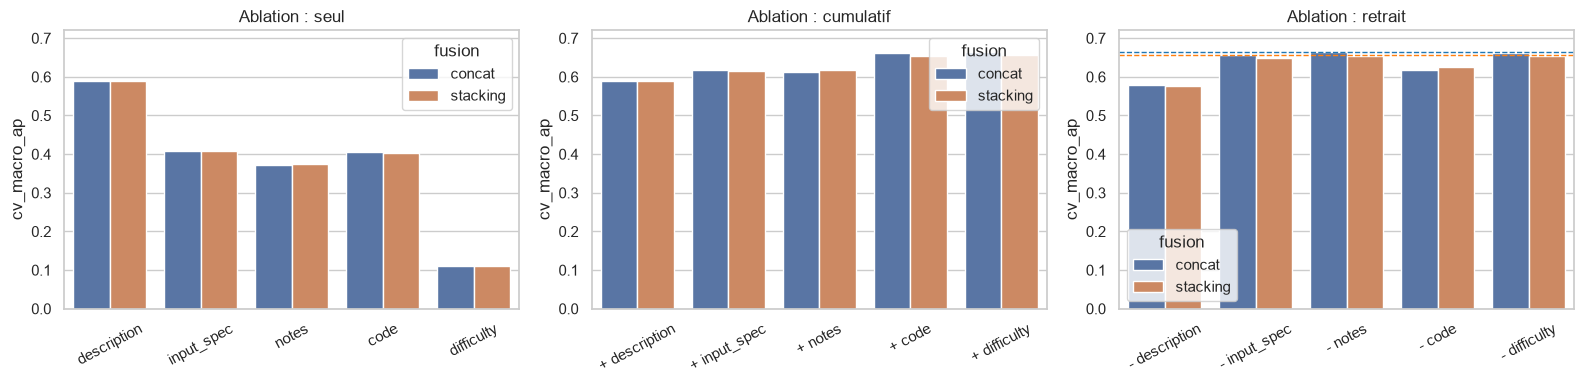

In [4]:
t0 = time.perf_counter()
cumulative = [DENSE_BLOCKS[: i + 1] for i in range(len(DENSE_BLOCKS))]
leave_one_out = [[b for b in DENSE_BLOCKS if b != removed] for removed in DENSE_BLOCKS]
experiments = (
    [("seul", [b], b) for b in DENSE_BLOCKS]
    + [("cumulatif", names, "+ " + names[-1]) for names in cumulative]
    + [("retrait", names, "- " + removed) for names, removed in zip(leave_one_out, DENSE_BLOCKS)]
)
ablation = pd.DataFrame(
    [
        {"type": kind, "blocs": label, "fusion": fusion, "cv_macro_ap": mean, "cv_std": std}
        for kind, names, label in experiments
        for fusion, make_model in FUSIONS.items()
        for mean, std in [cv_score(make_model, names)]
    ]
)
print(f"Ablation dense terminée en {time.perf_counter() - t0:.0f}s")
display(ablation.pivot_table(index=["type", "blocs"], columns="fusion", values="cv_macro_ap", sort=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kind in zip(axes, ["seul", "cumulatif", "retrait"]):
    sns.barplot(data=ablation[ablation["type"] == kind], x="blocs", y="cv_macro_ap", hue="fusion", ax=ax)
    ax.set(title=f"Ablation : {kind}", xlabel="", ylim=(0, 0.72))
    ax.tick_params(axis="x", rotation=28)
full = ablation[(ablation["type"] == "cumulatif") & (ablation["blocs"] == "+ " + DENSE_BLOCKS[-1])]
for _, row in full.iterrows():
    axes[2].axhline(row["cv_macro_ap"], linestyle="--", linewidth=1, color="tab:blue" if row["fusion"] == "concat" else "tab:orange")
plt.tight_layout()
plt.show()


In [5]:
# Apport des blocs TF-IDF ajoutés au stacking dense (embeddings + difficulté)
tfidf_variants = {
    "embeddings + difficulté": DENSE_BLOCKS,
    "+ tfidf_desc": DENSE_BLOCKS + ["tfidf_desc"],
    "+ tfidf_code": DENSE_BLOCKS + ["tfidf_code"],
    "+ tfidf_desc + tfidf_code": DENSE_BLOCKS + list(TFIDF_BLOCKS),
}
tfidf_ablation = pd.DataFrame(
    {label: cv_score(lambda names: StackingTagger(names, FEATURE_CFG), names) for label, names in tfidf_variants.items()},
    index=["cv_macro_ap", "cv_std"],
).T
BEST_VARIANT = tfidf_ablation["cv_macro_ap"].idxmax()
print("Variante retenue :", BEST_VARIANT)
tfidf_ablation.round(4)


Variante retenue : + tfidf_desc


,cv_macro_ap,cv_std
embeddings + difficulté,0.6557,0.0185
+ tfidf_desc,0.6626,0.0181
+ tfidf_code,0.6490,0.0191
+ tfidf_desc + tfidf_code,0.6588,0.0185


## 4. Interprétabilité du Stacking : quel bloc décide pour quel tag ?


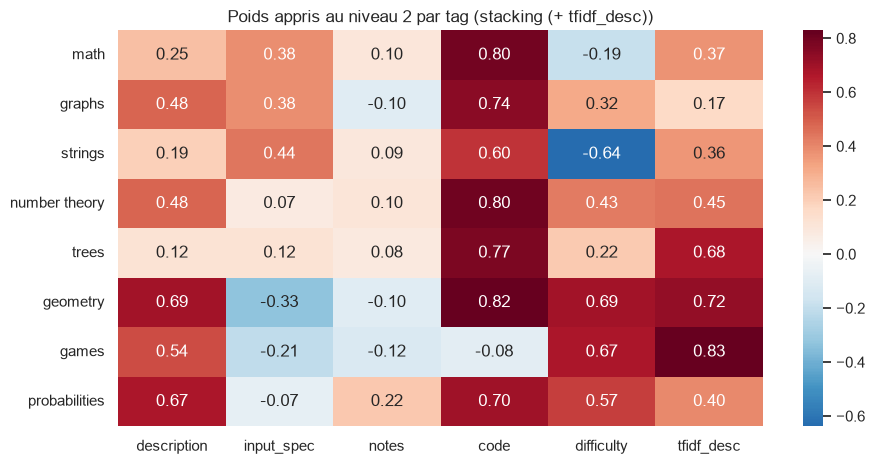

In [6]:
train_df, val_df, test_df = (df.iloc[data.positions[s]] for s in ("train", "val", "test"))
train_labels = build_label_matrix(train_df["tags"])

# Entraînement des modèles de référence et de fusion (train -> seuils sur val -> test)
kw_tagger = fit_keyword_tagger(train_df["prob_desc_description"], train_df["source_code"], train_labels, RegexConfig())
kw_tagger.choose_code_usage(val_df["prob_desc_description"], val_df["source_code"], y["val"])

trained_models = {
    "benchmark (SBERT desc)": build_logreg(LogRegConfig()),
    "concat (dense)": FUSIONS["concat"](DENSE_BLOCKS),
    "stacking (dense)": FUSIONS["stacking"](DENSE_BLOCKS),
    f"stacking ({BEST_VARIANT})": StackingTagger(tfidf_variants[BEST_VARIANT], FEATURE_CFG),
}
BEST_MODEL = f"stacking ({BEST_VARIANT})"

def _inp(name: str, split: str):
    return x[split]["description"] if name.startswith("benchmark") else x[split]

thresholds, predictions, fitted = {}, {}, {}
predictions["toujours oui"] = np.ones_like(y["test"])
predictions["regex_manuel"] = RegexTagger().predict(test_df["text_clean"])
predictions["regex_tfidf"] = kw_tagger.predict(test_df["prob_desc_description"], test_df["source_code"])

for name, model in trained_models.items():
    fitted[name] = model.fit(_inp(name, "train"), y["train"])
    thresholds[name] = tune_thresholds(y["val"], model.predict_proba(_inp(name, "val")))
    predictions[name] = apply_thresholds(model.predict_proba(_inp(name, "test")), thresholds[name])

coefs = fitted[BEST_MODEL].meta_coefficients(TARGET_TAGS)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(coefs, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title=f"Poids appris au niveau 2 par tag ({BEST_MODEL})")
plt.tight_layout()
plt.show()


## 5. Évaluation finale sur le Test Scellé & Plafond LLM (Zero-Shot)

On rassemble tous les jalons du projet sur les **726 exercices du test**. Lorsque le cache des prédictions du LLM `gemini-3.1-flash-lite` est présent dans `data/llm/`, on l'intègre en lecture seule à titre de **plafond de référence**.


,micro_f1,macro_f1,hamming_loss,jaccard_samples
toujours oui,0.158,0.149,0.914,0.086
regex_manuel,0.459,0.482,0.120,0.417
regex_tfidf,0.454,0.518,0.100,0.494
benchmark (SBERT desc),0.554,0.612,0.083,0.532
concat (dense),0.618,0.642,0.074,0.588
stacking (dense),0.622,0.646,0.074,0.602
stacking (+ tfidf_desc),0.627,0.647,0.072,0.600
LLM gemini-3.1-flash-lite (zero-shot),0.674,0.753,0.067,0.581


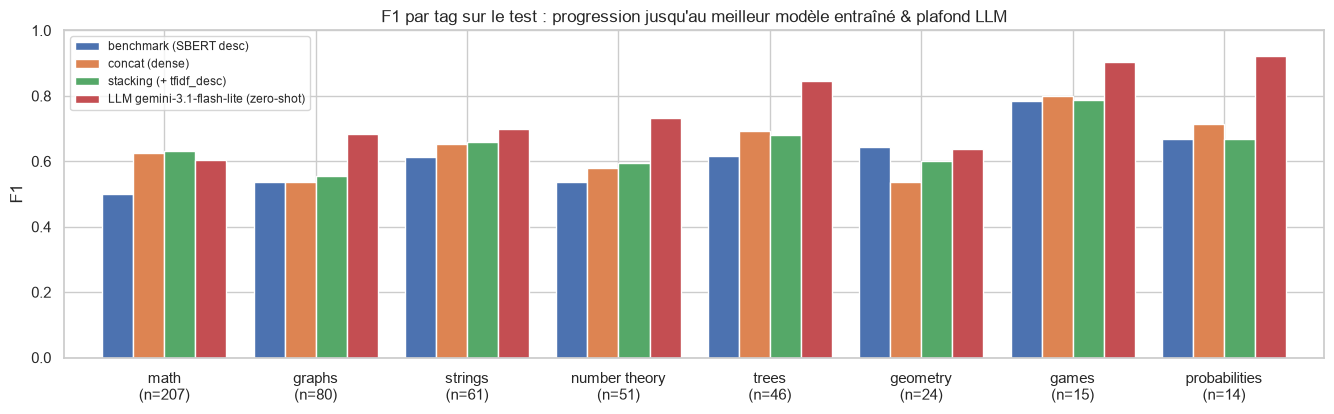

,precision,recall,f1,support,prevalence,f1_trivial,gain_vs_trivial (x)
math,0.57,0.71,0.63,207,0.29,0.44,1.42
graphs,0.52,0.60,0.55,80,0.11,0.20,2.80
strings,0.56,0.80,0.66,61,0.08,0.16,4.24
number theory,0.55,0.65,0.59,51,0.07,0.13,4.53
trees,0.67,0.70,0.68,46,0.06,0.12,5.71
geometry,0.46,0.88,0.60,24,0.03,0.06,9.38
games,0.72,0.87,0.79,15,0.02,0.04,19.46
probabilities,0.62,0.71,0.67,14,0.02,0.04,17.62


,diff_mean,ci_low,ci_high,p_a_better
stacking (dense) - benchmark (SBERT desc),0.034,0.003,0.065,0.985
stacking (+ tfidf_desc) - benchmark (SBERT desc),0.035,-0.001,0.073,0.974
stacking (+ tfidf_desc) - stacking (dense),0.001,-0.023,0.028,0.521
LLM gemini-3.1-flash-lite (zero-shot) - stacking (+ tfidf_desc),0.108,0.070,0.151,1.000


In [7]:
llm_cfg = LLMConfig(model="gemini-3.1-flash-lite")
llm_path = predictions_path("test", llm_cfg)
if llm_path.exists():
    llm_preds = load_predictions(llm_path)
    if len(llm_preds) == len(test_df):
        predictions[f"LLM {llm_cfg.model} (zero-shot)"] = to_label_matrix(llm_preds, test_df.index)

display(pd.DataFrame({name: global_metrics(y["test"], pred) for name, pred in predictions.items()}).T.round(3))

# Comparaison détaillée par tag pour les modèles clés
key_models = [m for m in ["benchmark (SBERT desc)", "concat (dense)", BEST_MODEL, f"LLM {llm_cfg.model} (zero-shot)"] if m in predictions]
f1_by_tag = pd.DataFrame({m: per_tag_metrics(y["test"], predictions[m], TARGET_TAGS)["f1"] for m in key_models})
support = y["test"].sum(axis=0)

fig, ax = plt.subplots(figsize=(13.5, 4.3))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.82)
ax.set(title="F1 par tag sur le test : progression jusqu'au meilleur modèle entraîné & plafond LLM", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TARGET_TAGS, support)])
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

# Gain par rapport au plancher trivial « toujours oui » + métriques détaillées du meilleur modèle entraîné
trivial = per_tag_metrics(y["test"], predictions["toujours oui"], TARGET_TAGS)
best_per_tag = per_tag_metrics(y["test"], predictions[BEST_MODEL], TARGET_TAGS)
best_per_tag["prevalence"] = trivial["precision"]
best_per_tag["f1_trivial"] = trivial["f1"]
best_per_tag["gain_vs_trivial (x)"] = best_per_tag["f1"] / trivial["f1"]
display(best_per_tag.round(2))

boot_pairs = [
    ("stacking (dense)", "benchmark (SBERT desc)"),
    (BEST_MODEL, "benchmark (SBERT desc)"),
    (BEST_MODEL, "stacking (dense)"),
]
if f"LLM {llm_cfg.model} (zero-shot)" in predictions:
    boot_pairs.append((f"LLM {llm_cfg.model} (zero-shot)", BEST_MODEL))
display(
    pd.DataFrame(
        {f"{a} - {b}": bootstrap_macro_f1_diff(y["test"], predictions[a], predictions[b], TUNING_CFG.n_bootstrap) for a, b in boot_pairs}
    ).T.round(3)
)


## 6. Analyse d'erreurs, latence d'inférence & pistes d'amélioration


In [8]:
best_pred = predictions[BEST_MODEL]
err_df = pd.DataFrame(
    {
        "faux_positifs": ((best_pred == 1) & (y["test"] == 0)).sum(axis=0),
        "faux_negatifs": ((best_pred == 0) & (y["test"] == 1)).sum(axis=0),
        "support": support,
    },
    index=TARGET_TAGS,
)
display(err_df)

llm_key = f"LLM {llm_cfg.model} (zero-shot)"
if llm_key in predictions:
    k_math = TARGET_TAGS.index("math")
    disagree = predictions[llm_key][:, k_math] != best_pred[:, k_math]
    stack_wins = (best_pred[disagree, k_math] == y["test"][disagree, k_math]).sum()
    llm_wins = (predictions[llm_key][disagree, k_math] == y["test"][disagree, k_math]).sum()
    print(f"Désaccords sur 'math' : {disagree.sum()} | stacking a raison {stack_wins} fois vs LLM {llm_wins} fois")

for kind, tag in [("fn", "math"), ("fp", "graphs")]:
    k = TARGET_TAGS.index(tag)
    pred, true = best_pred[:, k], y["test"][:, k]
    mask = (pred == 1) & (true == 0) if kind == "fp" else (pred == 0) & (true == 1)
    print(f"\n=== {tag} ({kind.upper()}) ===")
    for sid, row in test_df[mask].head(2).iterrows():
        print(f"  [{sid}] tags={row['tags']} -> {row['prob_desc_description'][:150]}...")

# Mesure de latence de bout en bout (SBERT x3 + UniXcoder + TF-IDF + Stacking + Seuils)
t0 = time.perf_counter()
text_encoder = load_encoder(FEATURE_CFG.text_model)
code_encoder = load_encoder(FEATURE_CFG.code_model, FEATURE_CFG.code_max_seq_length)
load_time = time.perf_counter() - t0

best_fitted, best_th = fitted[BEST_MODEL], thresholds[BEST_MODEL]
encode_blocks(test_df.iloc[:1], text_encoder, code_encoder)  # warm-up
latencies = []
for i in range(50):
    ts = time.perf_counter()
    feats = encode_blocks(test_df.iloc[[i]], text_encoder, code_encoder)
    apply_thresholds(best_fitted.predict_proba(feats), best_th)
    latencies.append(time.perf_counter() - ts)
print(f"Chargement des encodeurs : {load_time:.1f} s (une fois)")
print(f"Latence par exemple : médiane {np.median(latencies)*1000:.0f} ms, max {np.max(latencies)*1000:.0f} ms (contrainte < 10 s)")


,faux_positifs,faux_negatifs,support
math,112,60,207
graphs,45,32,80
strings,39,12,61
number theory,27,18,51
trees,16,14,46
geometry,25,3,24
games,5,2,15
probabilities,6,4,14


Désaccords sur 'math' : 168 | stacking a raison 110 fois vs LLM 58 fois

=== math (FN) ===
  [40] tags=['number theory', 'bitmasks', 'math', 'strings'] -> You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t...
  [161] tags=['implementation', 'probabilities', 'math'] -> Vasya and Kolya play a game with a string, using the following rules. Initially, Kolya creates a string s, consisting of small English letters, and un...

=== graphs (FP) ===
  [64] tags=['dfs and similar'] -> Fox Ciel is playing a mobile puzzle game called "Two Dots". The basic levels are played on a board of size n × m cells, like this:Each cell contains a...
  [81] tags=['implementation'] -> The research center Q has developed a new multi-core processor. The processor consists of n cores and has k cells of cache memory. Consider the work o...


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 11336.26it/s]

Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 43357.05it/s]

Chargement des encodeurs : 2.3 s (une fois)
Latence par exemple : médiane 65 ms, max 136 ms (contrainte < 10 s)


### Synthèse des résultats & perspectives

1. **Gain net de la multimodalité** : passer de la description seule (**0,612** Macro-F1 / 0,554 Micro-F1) au **Stacking (`embeddings + difficulté + tfidf_desc`)** porte le modèle à **0,647 de Macro-F1** (**0,627** Micro-F1, **0,600** Jaccard, Hamming **0,072**).
2. **Le code source (UniXcoder) est la 2e source la plus décisive** : il pèse le plus lourd au niveau 2 pour **7 tags sur 8**, et particulièrement sur `math` (**0,80** contre 0,25 pour la description) où le raisonnement apparaît dans la solution plutôt que dans l'énoncé.
3. **Les signaux lexicaux (`tfidf_desc`) complètent les embeddings** (+0,007 Macro-AP en CV), en particulier pour `games` (poids 0,83), `geometry` (0,72) et `trees` (0,68). À l'inverse, `notes` et `tfidf_code` n'apportent rien ou dégradent légèrement.
4. **Comparaison au plafond LLM (`gemini-3.1-flash-lite` zero-shot)** : le LLM atteint **0,753 de Macro-F1** sur les tags conceptuels rares (`probabilities` 0,92, `trees` 0,85, `games` 0,90), mais souffre de sur-étiquetage (Jaccard inférieur **0,581** vs **0,600**) et **perd contre le stacking sur `math`** (0,60 vs **0,63**), car seul le modèle entraîné apprend la convention d'annotation restrictive de Codeforces.
5. **Respect des contraintes opérationnelles** : modèle local déterministe, gratuit à l'usage, et inférence en **~60 ms** en médiane (plus de **150× sous la limite de 10 s**).

**Prochaines étapes (Partie 2 / Mise en production)**
- Élaguer `notes` et `tfidf_code` pour alléger l'inférence (un encodage SBERT en moins).
- Calibrer les seuils sur les probabilités **out-of-fold** (~4 100 exemples) plutôt que sur la seule validation (725) pour stabiliser les tags rares.
- Encapsuler le pipeline entraîné (`ExerciseClassifier` + CLI `src/cli.py` + tests `pytest`).
